# Lab 3: Noise Modeling and Modulation Foundations

In this lab, you will explore the characteristics of channel noise using your SDRs and build a fundamental understanding of how digital modulation schemes behave when subjected to that noise.

## Task 1: Modeling of Gaussian Noise

We will capture the noise from the channel by transmitting constant, known symbols and observing how they are scattered upon reception. You will reuse the coarse frequency correction from Lab 2 to lock onto the signal before isolating the noise.

In [40]:
# Done in Lab 1 and 2
import numpy as np
import matplotlib.pyplot as plt
import adi
import time

# --- Hardware Setup ---
fs = int(0.6e6)      # Sample rate: 2.0 MHz[cite: 1]
fc = int(763e6)      # Carrier frequency
tx_scale = 2**14     # DAC full-scale headroom[cite: 1]

# Connect to SDRs
tx_sdr = adi.Pluto("ip:192.168.3.1") #[cite: 1]
rx_sdr = adi.Pluto("ip:192.168.2.1") #[cite: 1]

tx_sdr.sample_rate = fs
tx_sdr.tx_lo = fc
tx_sdr.tx_rf_bandwidth = fs
tx_sdr.tx_hardwaregain_chan0 = -10

rx_sdr.sample_rate = fs

rx_sdr.rx_lo = fc
rx_sdr.rx_rf_bandwidth = fs
rx_sdr.gain_control_mode_chan0 = "manual"
rx_sdr.rx_hardwaregain_chan0 = 30
rx_sdr.rx_buffer_size = 200000

# # --- Transmit 1,1,1,1... (1D fixed points) ---
tx_symbols_1d = np.ones(10000, dtype=np.complex64) * tx_scale
tx_sdr.tx_cyclic_buffer = True #[cite: 1]
tx_sdr.tx(tx_symbols_1d)
time.sleep(0.5)

# Receive
rx_samples_1d = rx_sdr.rx()
tx_sdr.tx_destroy_buffer()

## Task 1: Modeling 1D Gaussian Noise

Transmit a constant stream of maximum-amplitude real symbols (DC).

**Instructions & Questions:**
1. **Intermediate Plot:** Plot the first 200 raw time-domain samples (Real and Imaginary). Observe the y-axis: is the signal centered at zero? Why or why not?
2. Strip the DC offset from the received samples.
3. Apply coarse frequency synchronization (using phase differentials)(done in Lab 2) .
4. **Final Plot:** Subtract the mean signal estimate to isolate the channel noise. Plot a 60-bin histogram of the real component of the noise.

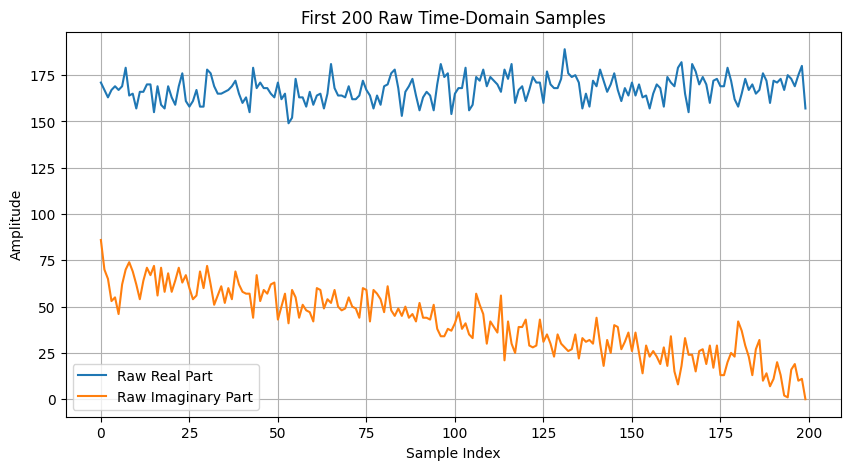

Observation for the first 200 raw time-domain samples: The signal is likely not centered at zero due to potential DC offsets introduced by the hardware or environment.


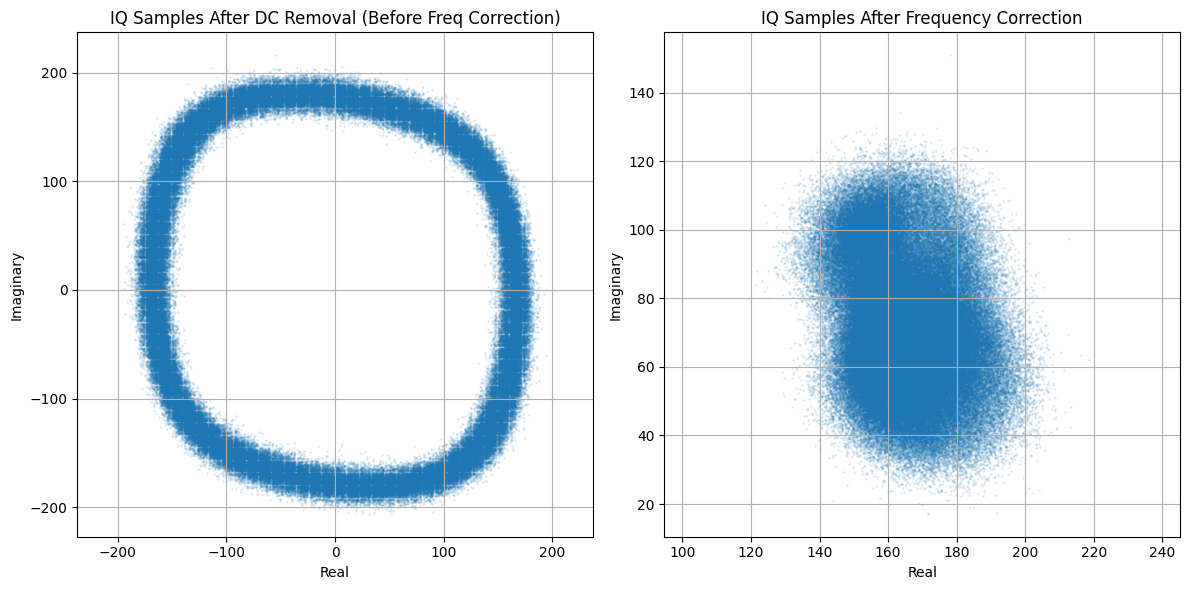

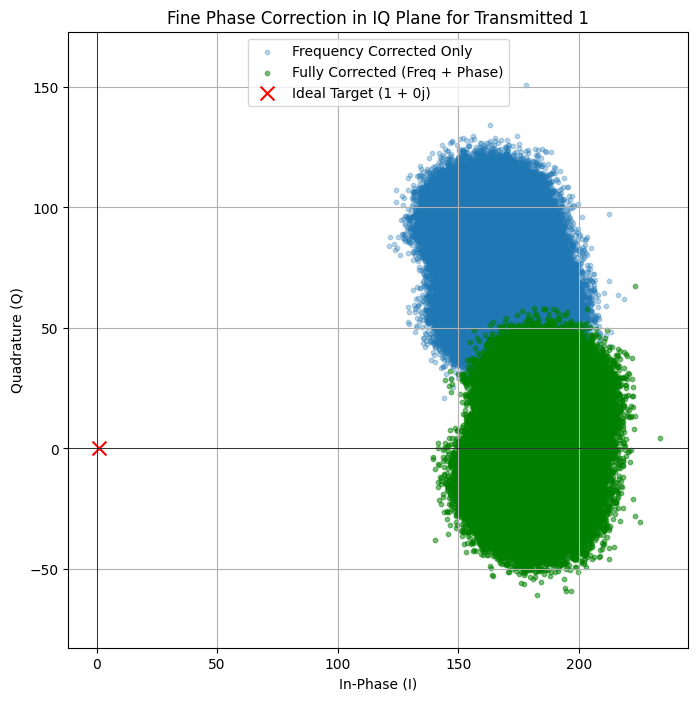

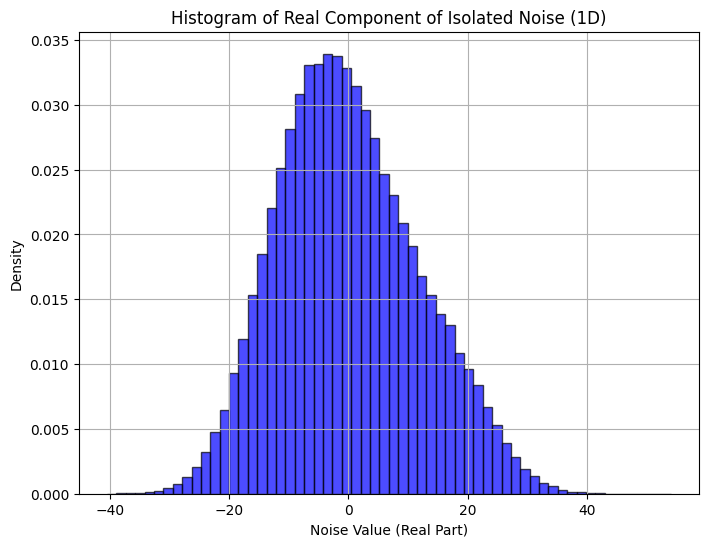

Variance of the real part of isolated noise: 139.4944
Variance of the imaginary part of isolated noise: 352.8337
Overall variance of complex isolated noise: 492.3281


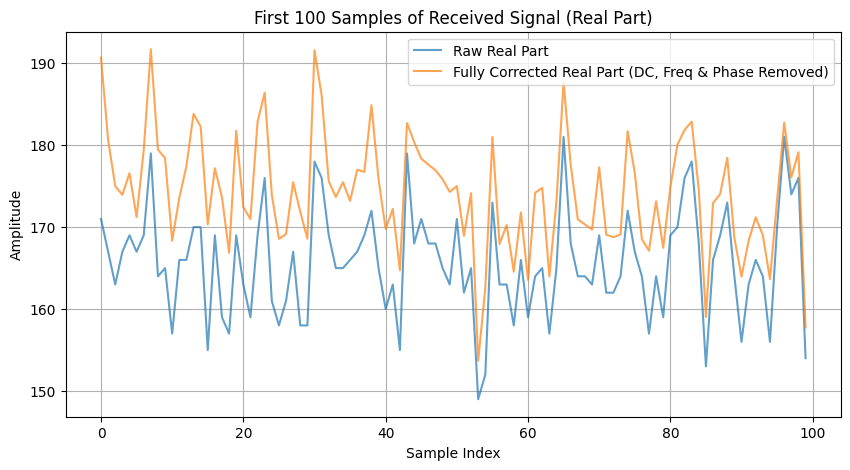

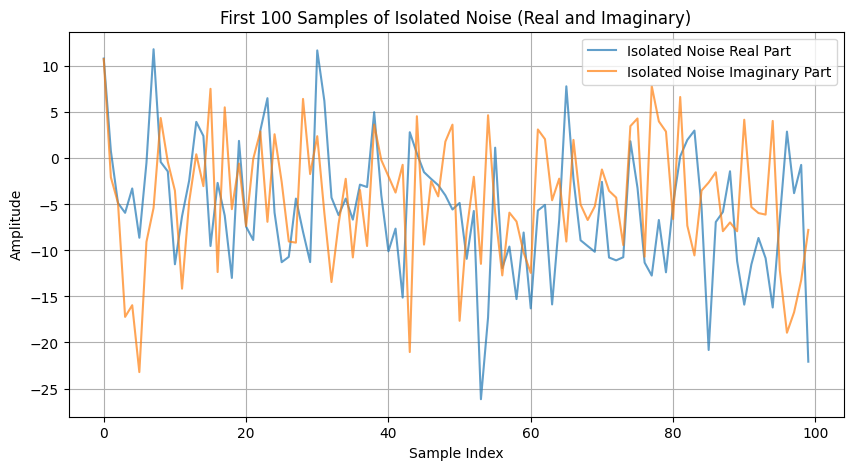

In [129]:
# Intermediate Plot: Plot the first 200 raw time-domain samples (Real and Imaginary).
plt.figure(figsize=(10, 5))
plt.plot(rx_samples_1d.real[:200], label='Raw Real Part')
plt.plot(rx_samples_1d.imag[:200], label='Raw Imaginary Part')
plt.title('First 200 Raw Time-Domain Samples')
plt.xlabel('Sample Index')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)
plt.show()
print("Observation for the first 200 raw time-domain samples: The signal is likely not centered at zero "
      "due to potential DC offsets introduced by the hardware or environment.")


###################################################################
# TODO: Coarse Frequency Correction & 1D Noise Histogram
###################################################################

# 1. Place the coarse frequency correction you implemented in Lab 2 over here. Plot the received IQ before and after correction
#    (conjugate multiplication and estimation).

# Remove DC offset from the received samples as per Task 1, instruction 2.
rx_samples_1d_dc_removed = rx_samples_1d - np.mean(rx_samples_1d)

# Estimate frequency offset using phase differentials for coarse correction
# A common method is to compute the average phase change between consecutive samples
# of the DC-removed signal.
# We are transmitting a constant symbol (1), so ideally, any phase rotation is due to frequency offset.
# Compute the phase differences of consecutive samples using conjugate product.
product = rx_samples_1d_dc_removed[1:] * np.conj(rx_samples_1d_dc_removed[:-1])
# The angle of 'product' gives the phase change between samples.
# The mean of these phase changes is the estimated frequency offset per sample (in radians).
freq_offset_radians_per_sample = np.mean(np.angle(product))

# Generate the correction phasor: e^(-j * freq_offset * n)
n = np.arange(len(rx_samples_1d))
correction_phasor = np.exp(-1j * freq_offset_radians_per_sample * n)

# Apply frequency correction
rx_corrected = rx_samples_1d_dc_removed * correction_phasor

# Plot IQ before (after DC removal but before freq correction) and after frequency correction
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.scatter(rx_samples_1d_dc_removed.real, rx_samples_1d_dc_removed.imag, alpha=0.1, s=1)
plt.title('IQ Samples After DC Removal (Before Freq Correction)')
plt.xlabel('Real')
plt.ylabel('Imaginary')
plt.grid(True)
plt.axis('equal') # Keep aspect ratio for constellation plots

plt.subplot(1, 2, 2)
plt.scatter(rx_corrected.real, rx_corrected.imag, alpha=0.1, s=1)
plt.title('IQ Samples After Frequency Correction')
plt.xlabel('Real')
plt.ylabel('Imaginary')
plt.grid(True)
plt.axis('equal') # Keep aspect ratio for constellation plots

plt.tight_layout()
plt.show()


# --- Fine Phase Correction (User requested adaptation) ---
# The following section implements fine phase correction.
# Note: The target_phase is set to 0.0 because for this 1D case, a real '1' was transmitted,
# so the ideal constellation point should lie on the positive real axis (phase = 0).

# 1. Calculate the mean of the frequency-corrected points
mean_rx_after_freq_corr = np.mean(rx_corrected)

# 2. Find the current phase angle of that mean cluster
current_phase_after_freq_corr = np.angle(mean_rx_after_freq_corr)

# 3. Define the target phase (0 radians for transmitted symbol '1')
target_phase_for_1 = 0.0

# 4. Calculate the required phase rotation to get to the target
phase_rotation_fine = target_phase_for_1 - current_phase_after_freq_corr

# 5. Apply the phase rotation to all samples
rx_fully_corrected = rx_corrected * np.exp(1j * phase_rotation_fine)


# --- Plot to verify fine phase correction ---
plt.figure(figsize=(8, 8))
# Plot the frequency-corrected points before fine phase correction
plt.scatter(rx_corrected.real, rx_corrected.imag, s=10, alpha=0.3, label='Frequency Corrected Only')

# Plot the new phase-corrected points (Fully Corrected)
plt.scatter(rx_fully_corrected.real, rx_fully_corrected.imag, s=10, alpha=0.5, color='green', label='Fully Corrected (Freq + Phase)')

# Mark the ideal target symbol (1+0j for transmitted '1')
plt.scatter([1], [0], color='red', marker='x', s=100, label='Ideal Target (1 + 0j)')

plt.xlabel('In-Phase (I)')
plt.ylabel('Quadrature (Q)')
plt.title('Fine Phase Correction in IQ Plane for Transmitted 1')
plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=0.5)
plt.grid(True)
plt.legend()
plt.axis('equal')
plt.show()


# 2. Write the code for subtracting the expected received signal (the '1's)
#    from your corrected samples to isolate the noise.
# Since we transmitted '1' (real) and applied frequency and phase correction,
# the expected received signal is the mean of the fully corrected samples.
# Subtracting this mean effectively centers the signal at (0,0), isolating the noise.
mean_signal_estimate = np.mean(rx_fully_corrected) # Use rx_fully_corrected
noise_1d = rx_fully_corrected - mean_signal_estimate # Use rx_fully_corrected


# 3. Plot the histogram of the real part of the isolated noise along the x-axis.
#    It should resemble a Gaussian (normal) distribution.
plt.figure(figsize=(8, 6))
plt.hist(noise_1d.real, bins=60, density=True, alpha=0.7, color='blue', edgecolor='black')
plt.title('Histogram of Real Component of Isolated Noise (1D)')
plt.xlabel('Noise Value (Real Part)')
plt.ylabel('Density')
plt.grid(True)
plt.show()


# --- VISUALIZATION & INSIGHT TIPS ---
# TIP: Print the variance (np.var) of your isolated noise.
print(f"Variance of the real part of isolated noise: {np.var(noise_1d.real):.4f}")
print(f"Variance of the imaginary part of isolated noise: {np.var(noise_1d.imag):.4f}")
print(f"Overall variance of complex isolated noise: {np.var(noise_1d):.4f}")


# TIP: Plot the first 100 samples of the received signal against time (plt.plot).
#      You should visually see the noise "riding" on top of the constant DC level.
plt.figure(figsize=(10, 5))
plt.plot(rx_samples_1d.real[:100], label='Raw Real Part', alpha=0.7)
plt.plot(rx_fully_corrected.real[:100], label='Fully Corrected Real Part (DC, Freq & Phase Removed)', alpha=0.7) # Use rx_fully_corrected
plt.title('First 100 Samples of Received Signal (Real Part)')
plt.xlabel('Sample Index')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)
plt.show()

# Also plotting the isolated noise for clarity
plt.figure(figsize=(10, 5))
plt.plot(noise_1d.real[:100], label='Isolated Noise Real Part', alpha=0.7)
plt.plot(noise_1d.imag[:100], label='Isolated Noise Imaginary Part', alpha=0.7)
plt.title('First 100 Samples of Isolated Noise (Real and Imaginary)')
plt.xlabel('Sample Index')
plt.ylabel('Amplitude')
plt.legend()
plt.grid(True)
plt.show()


> **Stop and Ponder:** Think about the frequency correction step you just performed. Why is it absolutely crucial to correct the frequency offset *before* attempting to isolate and plot the noise? What would your histogram look like if the frequency offset was still present?

### Complex Noise (2D)
Now we will repeat the experiment but transmit $1+1j$ to observe noise in the complex plane.
Transmit the complex symbol `1 + 1j` scaled appropriately.

**Instructions & Questions:**
1. Strip the DC offset and perform coarse frequency correction.
2. **Intermediate Plot:** Before subtracting the signal mean, plot the locked complex constellation scatter plot. Overlay the mean estimate as a prominent red marker.
3. **Final Plot:** Subtract the mean to center the cluster at (0,0) and generate a 2D histogram (heatmap) of the complex noise.

In [2]:
# # --- Transmit 1+1j (Complex fixed points) ---
tx_symbols_2d = (np.ones(10000) + 1j*np.ones(10000)).astype(np.complex64) * (tx_scale / np.sqrt(2))
tx_sdr.tx_cyclic_buffer = True #[cite: 1]
tx_sdr.tx(tx_symbols_2d)
time.sleep(0.5)

# Receive
rx_samples_2d = rx_sdr.rx()
tx_sdr.tx_destroy_buffer()

NameError: name 'np' is not defined

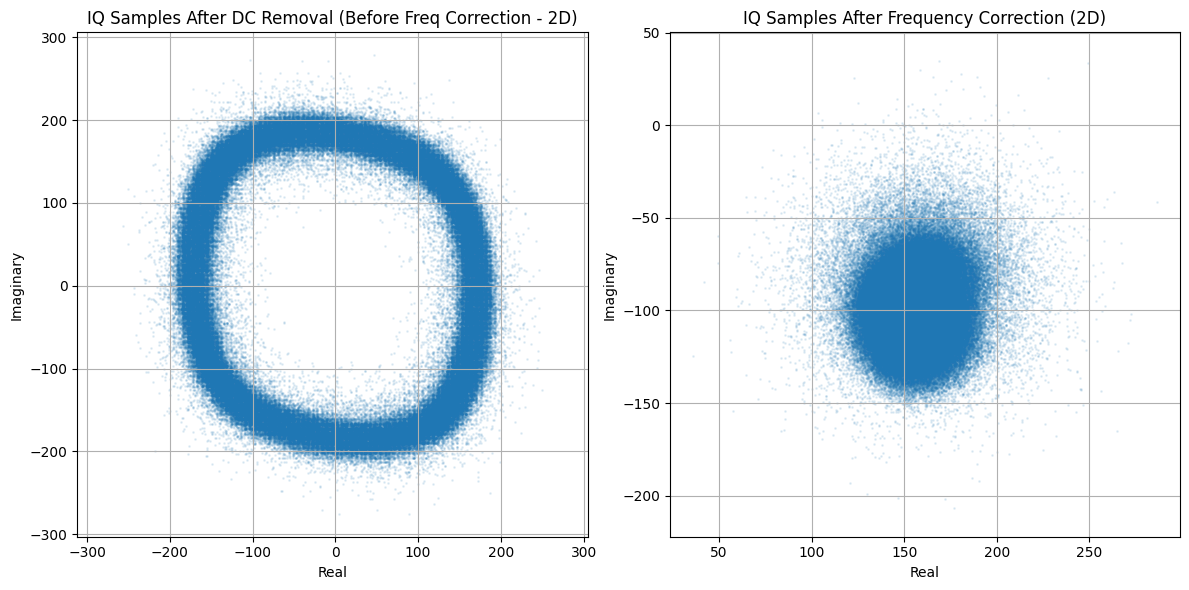

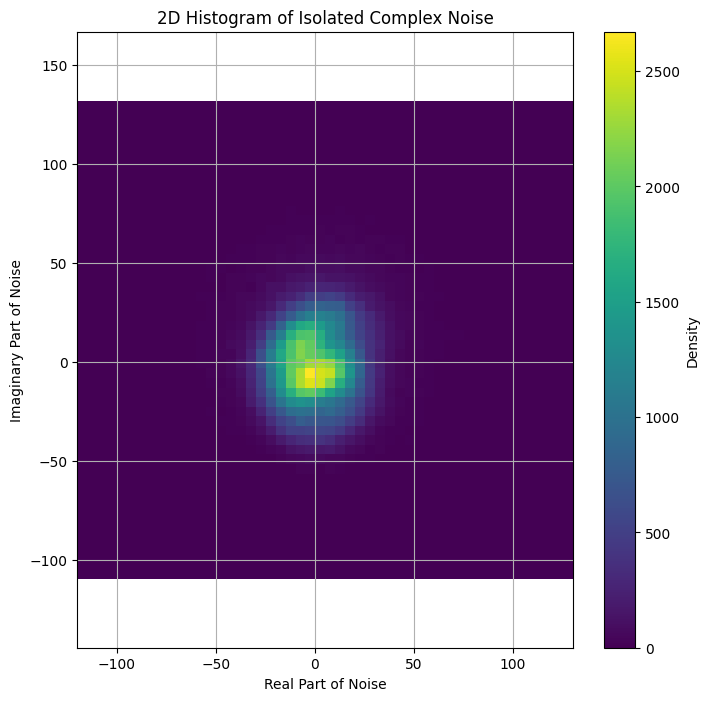

Covariance Matrix of Real and Imaginary Noise Components:
[[286.25550879  17.35505366]
 [ 17.35505366 397.31898609]]
Observation: The off-diagonal elements of the covariance matrix should be close to zero,indicating that the real and imaginary parts of the noise are largely uncorrelated (independent).The diagonal elements represent the variances of the real and imaginary parts, which should be approximately equal for circular Gaussian noise.


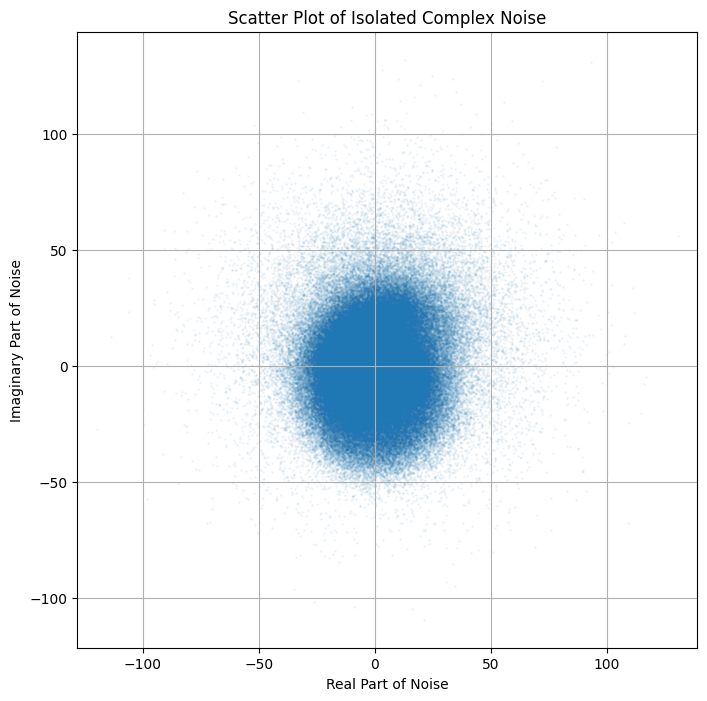

In [131]:
###################################################################
# TODO: Coarse Frequency Correction & 2D Noise Histogram
###################################################################

# 1. Apply the coarse frequency correction to rx_samples_2d. Plot IQ before and after correction

# Remove DC offset from the received samples
rx_samples_2d_dc_removed = rx_samples_2d - np.mean(rx_samples_2d)

# Estimate frequency offset using phase differentials for coarse correction
# (Same method as for 1D, since it applies to the complex envelope)
product_2d = rx_samples_2d_dc_removed[1:] * np.conj(rx_samples_2d_dc_removed[:-1])
freq_offset_radians_per_sample_2d = np.mean(np.angle(product_2d))

# Generate the correction phasor
n_2d = np.arange(len(rx_samples_2d))
correction_phasor_2d = np.exp(-1j * freq_offset_radians_per_sample_2d * n_2d)

# Apply frequency correction
rx_corrected_2d = rx_samples_2d_dc_removed * correction_phasor_2d

# Plot IQ before (after DC removal but before freq correction) and after frequency correction
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.scatter(rx_samples_2d_dc_removed.real, rx_samples_2d_dc_removed.imag, alpha=0.1, s=1)
plt.title('IQ Samples After DC Removal (Before Freq Correction - 2D)')
plt.xlabel('Real')
plt.ylabel('Imaginary')
plt.grid(True)
plt.axis('equal') # Keep aspect ratio for constellation plots

plt.subplot(1, 2, 2)
plt.scatter(rx_corrected_2d.real, rx_corrected_2d.imag, alpha=0.1, s=1)
plt.title('IQ Samples After Frequency Correction (2D)')
plt.xlabel('Real')
plt.ylabel('Imaginary')
plt.grid(True)
plt.axis('equal') # Keep aspect ratio for constellation plots

plt.tight_layout()
plt.show()


# 2. Subtract the expected 1+1j signal to isolate the complex noise.
# The expected signal is the mean of the corrected samples, which should be close to 1+1j after all corrections.
mean_signal_estimate_2d = np.mean(rx_corrected_2d)
noise_2d = rx_corrected_2d - mean_signal_estimate_2d


# 3. Plot a 2D histogram (e.g., using plt.hist2d) of the real vs. imaginary
#    parts of the noise.
plt.figure(figsize=(8, 8))
plt.hist2d(noise_2d.real, noise_2d.imag, bins=50, cmap='viridis')
plt.colorbar(label='Density')
plt.title('2D Histogram of Isolated Complex Noise')
plt.xlabel('Real Part of Noise')
plt.ylabel('Imaginary Part of Noise')
plt.grid(True)
plt.axis('equal') # Ensure circular representation if noise is circular
plt.show()


# --- VISUALIZATION & INSIGHT TIPS ---
# TIP: Print the covariance matrix (np.cov) between the real and imaginary parts of the noise.
#      What should the off-diagonal elements be close to if the noise is truly independent?
noise_components = np.vstack([noise_2d.real, noise_2d.imag])
cov_matrix = np.cov(noise_components)
print(f"Covariance Matrix of Real and Imaginary Noise Components:\n{cov_matrix}")
print("Observation: The off-diagonal elements of the covariance matrix should be close to zero,"
      "indicating that the real and imaginary parts of the noise are largely uncorrelated (independent)."
      "The diagonal elements represent the variances of the real and imaginary parts, which should be approximately equal for circular Gaussian noise.")


# TIP: Try generating a simple scatter plot of the noise (plt.scatter) with a low alpha value
#      (e.g., alpha=0.1) to visually confirm the circular symmetry of the "cloud".
plt.figure(figsize=(8, 8))
plt.scatter(noise_2d.real, noise_2d.imag, alpha=0.05, s=1)
plt.title('Scatter Plot of Isolated Complex Noise')
plt.xlabel('Real Part of Noise')
plt.ylabel('Imaginary Part of Noise')
plt.grid(True)
plt.axis('equal')
plt.show()


> **Stop and Ponder:** If your 2D histogram or scatter plot turned out to be strictly elliptical (stretched out along one axis) instead of circular, what physical imperfections in the SDR hardware's I and Q channels might cause this?

## Task 2: Modulation Schemes and Decoding Intuition

*Note: This task is purely Python-based. No SDR hardware is required.*

In this task, we explore the mathematics of how we represent digital information and what happens when the types of noise you isolated in Task 1 corrupt those signals.

### Modulation and Noise
**BPSK (Binary Phase Shift Keying):** Symbols are distributed on a 1D line. The transmitted symbol $s$ is either positive or negative based on the signal energy $E_s$.
$$s \in \{+\sqrt{E_s}, -\sqrt{E_s}\}$$

**4-QAM (Quadrature Amplitude Modulation):** Symbols are distributed in a 2D complex plane.
$$s \in \{\pm \sqrt{E_s/2} \pm j\sqrt{E_s/2}\}$$

**Additive White Gaussian Noise (AWGN):** When a signal travels through a channel, it picks up noise. The received signal $y$ is the transmitted symbol $s$ plus noise $w$:
$$y = s + w$$

For 1D signals (like BPSK), the noise is purely Real Gaussian Noise (GN):
$$w \sim \mathbb{N}(0, \sigma^2)$$

For 2D signals (like 4-QAM), the noise is Complex Standard Circular Gaussian Noise (CSCGN). This is essentially a 2D Gaussian where the real and imaginary parts are independent:
$$w \sim \mathbb{CN}(0, \sigma^2) = \mathbb{N}(0, \sigma^2/2) + j\mathbb{N}(0, \sigma^2/2)$$

### Your Task
Suppose you receive a corrupted symbol $y$. If you know the transmitted symbol was chosen from a specific set of fixed points (like the BPSK or 4-QAM constellations), and the noise acts as a random, symmetric "cloud" or "nudge" in any direction, how would you intuitively decide which symbol was originally sent?

*Hint: Think about the geometry of the situation. If you are standing at point $y$, which constellation point makes the most logical sense to guess based on distance? Mathematically, if your ideal constellation points are $s_i$, you want to find the point that minimizes the Euclidean distance to $y$: $\arg\min_{s_i} |y - s_i|$. This intuitive geometric approach is exactly equivalent to **Maximum Likelihood (ML)** decoding for AWGN channels!*

**Implementation:** (Generate intermediate plots for visualization of each step)
1. Write code to generate arrays of random BPSK and 4-QAM symbols.
2. Add GN to your BPSK symbols and CSCGN to your 4-QAM symbols.
3. Implement your intuitive nearest-neighbor decoding logic to guess the original symbols from the noisy received ones.
4. Calculate the **Symbol Error Rate (SER)** (Number of incorrect guesses / Total symbols).
5. Test how the SER changes with varying **Signal-to-Noise Ratio (SNR)**. Fix your signal power (e.g., $E_s = 1$) and write a loop to sweep through a range of noise variances ($\sigma^2$) or visa-versa(Try both methods). Plot the calculated error rate on the y-axis against the noise variance or SNR on the x-axis to visualize the performance degradation.

> **Stop and Ponder:** As you artificially increase the noise power (making the noise clouds wider and wider), the distinct clusters of points will begin to overlap and merge. At what point does your intuitive geometric decoding logic start to fail? Is it a gradual increase in errors, or a sudden total failure?

Simulating BPSK and 4-QAM performance...
Simulation complete.


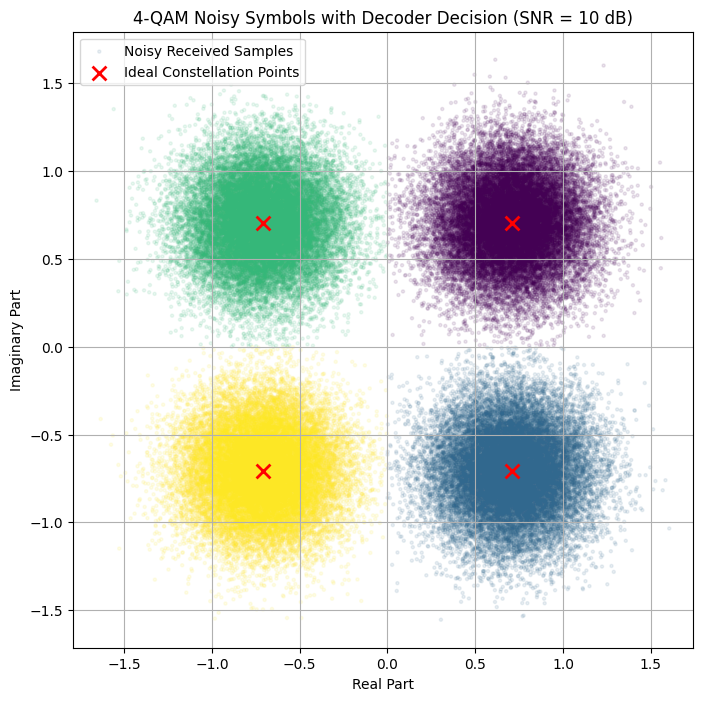

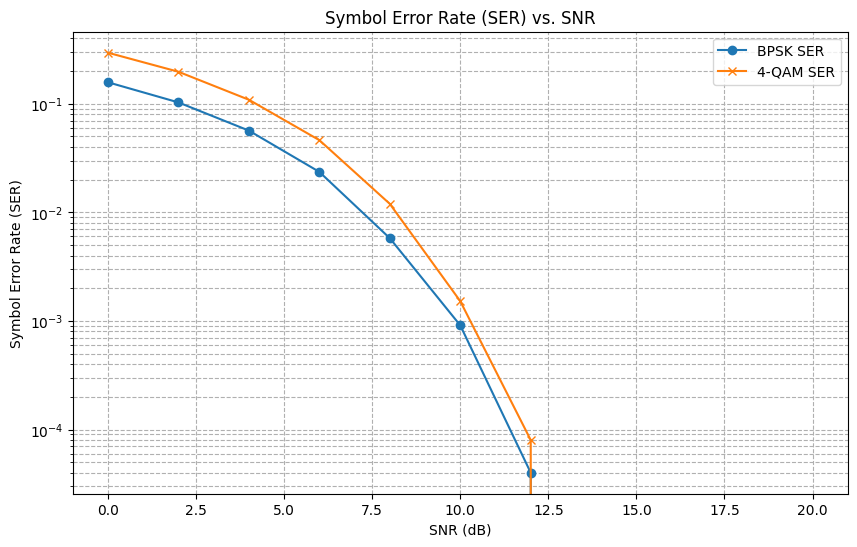

In [10]:
###################################################################
# TODO: Simulation, Noise Addition, and Decoding
###################################################################

# Write your Task 2 implementation here.

# --- Parameters ---
num_symbols = 100000  # Number of symbols to simulate
Es = 1.0              # Signal energy (for BPSK, it's the squared amplitude)

# Define the range of SNR in dB to test
snr_db_range = np.arange(0, 21, 2) # From 0 dB to 20 dB in steps of 2 dB

# Store SER results
ser_bpsk = []
ser_4qam = []

# BPSK Constellation Points: +/- sqrt(Es)
constellation_bpsk = np.array([-np.sqrt(Es), np.sqrt(Es)])

# 4-QAM Constellation Points: (+\-sqrt(Es/2) +/-\ j*sqrt(Es/2))
constellation_4qam_points = np.array([
    complex(np.sqrt(Es/2), np.sqrt(Es/2)),
    complex(np.sqrt(Es/2), -np.sqrt(Es/2)),
    complex(-np.sqrt(Es/2), np.sqrt(Es/2)),
    complex(-np.sqrt(Es/2), -np.sqrt(Es/2))
])

print("Simulating BPSK and 4-QAM performance...")

for snr_db in snr_db_range:
    # Calculate noise variance based on SNR
    snr_linear = 10**(snr_db / 10)

    # For BPSK (1D real noise), sigma^2 = Es / SNR_linear
    sigma_squared_bpsk = Es / snr_linear
    sigma_bpsk = np.sqrt(sigma_squared_bpsk)

    # For 4-QAM (2D complex noise), sigma_squared_N = Es / SNR_linear
    # Each real and imaginary component has variance sigma_squared_N / 2
    sigma_squared_4qam_per_comp = (Es / snr_linear) / 2 # Variance of real and imag parts
    sigma_4qam_per_comp = np.sqrt(sigma_squared_4qam_per_comp)

    # --- BPSK Simulation ---
    # Generate random BPSK symbols
    s_bpsk_tx = np.random.choice(constellation_bpsk, size=num_symbols)

    # Add AWGN
    w_bpsk = np.random.normal(0, sigma_bpsk, size=num_symbols)
    y_bpsk = s_bpsk_tx + w_bpsk

    # Decode BPSK (nearest neighbor)
    decoded_bpsk = np.zeros_like(y_bpsk)
    for i in range(num_symbols):
        distances = np.abs(y_bpsk[i] - constellation_bpsk)
        decoded_bpsk[i] = constellation_bpsk[np.argmin(distances)]

    # Calculate SER for BPSK
    errors_bpsk_count = np.sum(decoded_bpsk != s_bpsk_tx)
    ser_bpsk.append(errors_bpsk_count / num_symbols)

    # --- 4-QAM Simulation ---
    # Generate random 4-QAM symbols
    # Choose from the complex constellation points directly
    s_4qam_tx = np.random.choice(constellation_4qam_points, size=num_symbols)

    # Add CSCGN
    w_4qam_real = np.random.normal(0, sigma_4qam_per_comp, size=num_symbols)
    w_4qam_imag = np.random.normal(0, sigma_4qam_per_comp, size=num_symbols)
    w_4qam = w_4qam_real + 1j * w_4qam_imag
    y_4qam = s_4qam_tx + w_4qam

    # Decode 4-QAM (nearest neighbor)
    decoded_4qam = np.zeros_like(y_4qam)
    for i in range(num_symbols):
        distances = np.abs(y_4qam[i] - constellation_4qam_points)
        decoded_4qam[i] = constellation_4qam_points[np.argmin(distances)]

    # Calculate SER for 4-QAM
    errors_4qam_count = np.sum(decoded_4qam != s_4qam_tx)
    ser_4qam.append(errors_4qam_count / num_symbols)

print("Simulation complete.")

# --- VISUALIZATION & INSIGHT TIPS ---

# TIP: To verify your decoder works, plot your noisy 4-QAM symbols using a scatter plot.
#      Color-code the received points based on what your decoder *thinks* they are
#      (e.g., color points decoded as +1+1j red, -1+1j blue, etc.).
#      You should see clear decision boundaries form along the axes!

# Let's pick a moderate SNR for visualization (e.g., 10 dB)
visual_snr_db = 10
visual_snr_linear = 10**(visual_snr_db / 10)
visual_sigma_squared_4qam_per_comp = (Es / visual_snr_linear) / 2
visual_sigma_4qam_per_comp = np.sqrt(visual_sigma_squared_4qam_per_comp)

# Re-generate 4-QAM symbols and noise for visualization at a specific SNR
s_4qam_tx_viz = np.random.choice(constellation_4qam_points, size=num_symbols)
w_4qam_real_viz = np.random.normal(0, visual_sigma_4qam_per_comp, size=num_symbols)
w_4qam_imag_viz = np.random.normal(0, visual_sigma_4qam_per_comp, size=num_symbols)
w_4qam_viz = w_4qam_real_viz + 1j * w_4qam_imag_viz
y_4qam_viz = s_4qam_tx_viz + w_4qam_viz

decoded_4qam_viz = np.zeros_like(y_4qam_viz)
for i in range(num_symbols):
    distances = np.abs(y_4qam_viz[i] - constellation_4qam_points)
    decoded_4qam_viz[i] = constellation_4qam_points[np.argmin(distances)]

# Create a mapping from constellation point to color index
constellation_to_color_idx = {point: i for i, point in enumerate(constellation_4qam_points)}
colors = [constellation_to_color_idx[d] for d in decoded_4qam_viz]

plt.figure(figsize=(8, 8))
scatter = plt.scatter(y_4qam_viz.real, y_4qam_viz.imag, c=colors, cmap='viridis', alpha=0.1, s=5, label='Noisy Received Samples')
plt.scatter(constellation_4qam_points.real, constellation_4qam_points.imag, color='red', marker='x', s=100, linewidth=2, label='Ideal Constellation Points')
plt.title(f'4-QAM Noisy Symbols with Decoder Decision (SNR = {visual_snr_db} dB)')
plt.xlabel('Real Part')
plt.ylabel('Imaginary Part')
plt.grid(True)
plt.axis('equal')
plt.legend()
plt.show()

# TIP: Ensure you plot the final SER vs. Variance (or SNR) on a logarithmic y-axis
#      (plt.semilogy) to better visualize the steep drop-off in errors.
plt.figure(figsize=(10, 6))
plt.semilogy(snr_db_range, ser_bpsk, '-o', label='BPSK SER')
plt.semilogy(snr_db_range, ser_4qam, '-x', label='4-QAM SER')
plt.title('Symbol Error Rate (SER) vs. SNR')
plt.xlabel('SNR (dB)')
plt.ylabel('Symbol Error Rate (SER)')
plt.grid(True, which="both", ls="--")
plt.legend()
plt.show()


## Task: End-to-End BPSK over SDR

Now that you understand noise modeling and basic decision-making mathematically, try putting it all together on the hardware! In this bonus task, your goal is to implement a full BPSK transmission and reception pipeline over the air.

**The Flow:**
1. **Generate Symbols:** Create an array of random BPSK symbols (e.g., sequence of `+1`s and `-1`s).
2. **Transmit:** Scale them properly and send them through the `tx_sdr`.
3. **Receive:** Capture the raw samples via `rx_sdr`.
4. **Process:** Apply your coarse frequency correction. This is vital to stop the constellation from spinning in the complex plane so you can actually read the phase!
5. **Demodulate:** Extract the real part of the corrected signal and use the geometric intuition you developed in Task 2 to decode the received samples back into the original bits.

*(No code template is provided for this—use the modular pieces you've built in Labs 2 and 3 to construct the pipeline!)*

BPSK SYNCHRONIZATION
Estimated phase rotation/sample: -0.0023780405652014144 rad/sample
Estimated residual phase: -1.4617619199237415 rad


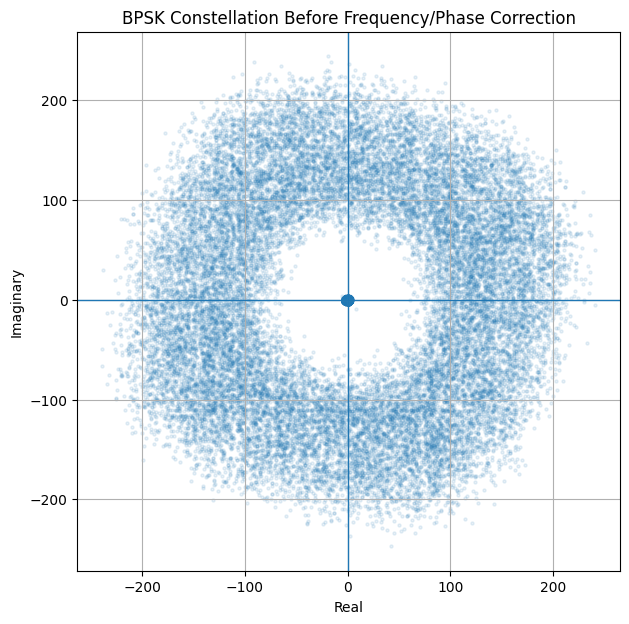

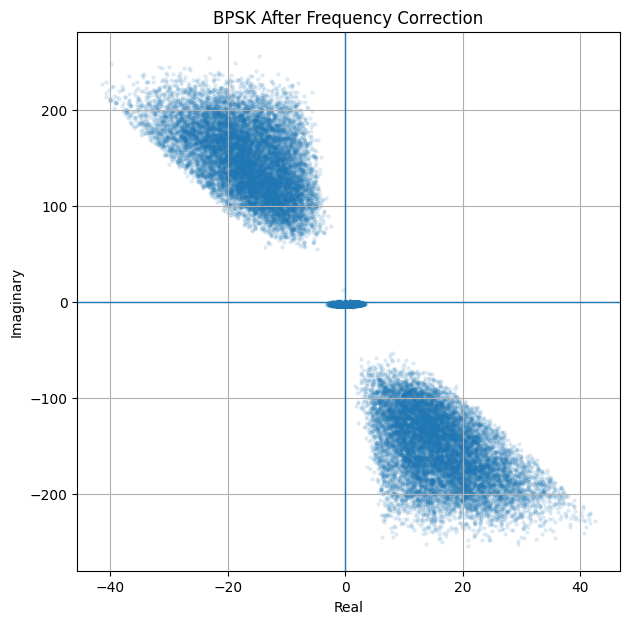

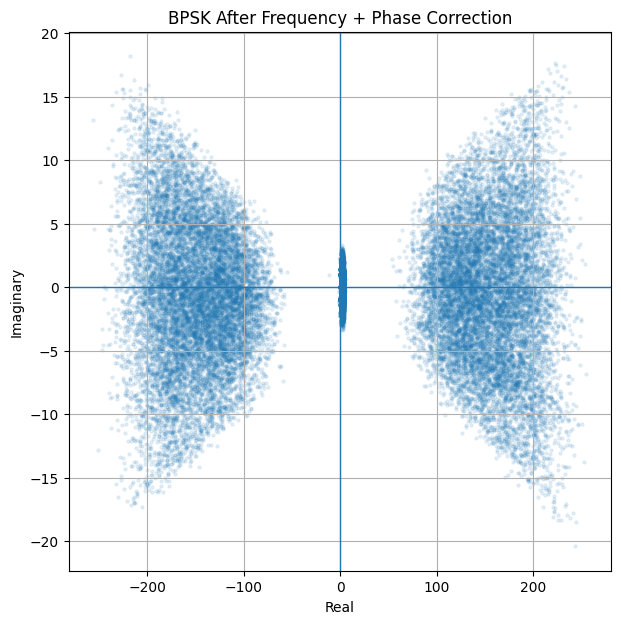

In [39]:
###################################################################
# Bonus Task: End-to-End BPSK over SDR
###################################################################

# ================================================================
# 1. Generate random BPSK symbols
# ================================================================

num_symbols = 10000

random_bits = np.random.randint(0, 2, num_symbols)

bpsk_symbols = (
    (2 * random_bits - 1)
    .astype(np.complex64)
    * (tx_scale / 2)
)


# ================================================================
# 2. Transmit
# ================================================================

tx_sdr.tx_cyclic_buffer = True
tx_sdr.tx(bpsk_symbols)

time.sleep(0.5)


# ================================================================
# 3. Receive
# ================================================================

rx_samples_bpsk = rx_sdr.rx()

tx_sdr.tx_destroy_buffer()


# ================================================================
# 4. Remove DC / LO leakage
# ================================================================

rx_no_dc = rx_samples_bpsk - np.mean(rx_samples_bpsk)


# ================================================================
# 5. COARSE FREQUENCY OFFSET ESTIMATION
# ================================================================
#
# BPSK has 180-degree phase transitions.
#
# Squaring removes the BPSK modulation:
#
#       (+1)^2 = 1
#       (-1)^2 = 1
#
# Therefore the remaining phase rotation is caused mainly
# by the carrier-frequency offset.
#
# ================================================================

squared_rx = rx_no_dc ** 2

phase_diff_sq = np.angle(
    squared_rx[1:] * np.conj(squared_rx[:-1])
)

# Remove unreliable samples if desired
# (very low-amplitude samples have unreliable phase)
valid = np.abs(squared_rx[1:]) > 0.01 * np.max(np.abs(squared_rx))

mean_phase_diff_sq = np.mean(
    phase_diff_sq[valid]
)

# Squaring doubles the phase rotation
cfo_phase_per_sample = mean_phase_diff_sq / 2


# ================================================================
# 6. FREQUENCY CORRECTION
# ================================================================

n = np.arange(len(rx_no_dc))

rx_freq_corrected = (
    rx_no_dc
    * np.exp(-1j * cfo_phase_per_sample * n)
)


# ================================================================
# 7. PHASE CORRECTION
# ================================================================
#
# After CFO correction, BPSK should ideally lie on one axis.
#
# We estimate the residual phase using:
#
#       phi = 0.5 * angle(mean(r^2))
#
# because squaring a BPSK signal removes the +/- ambiguity.
#
# ================================================================

phase_estimate = 0.5 * np.angle(
    np.mean(rx_freq_corrected ** 2)
)


# ================================================================
# 8. PHASE CORRECTION
# ================================================================

rx_corrected_bpsk = (
    rx_freq_corrected
    * np.exp(-1j * phase_estimate)
)


# ================================================================
# 9. BPSK DEMODULATION
# ================================================================

decoded_bits = (
    np.real(rx_corrected_bpsk) >= 0
).astype(np.uint8)


# ================================================================
# 10. Display estimated corrections
# ================================================================

print("================================================")
print("BPSK SYNCHRONIZATION")
print("================================================")

print(
    "Estimated phase rotation/sample:",
    cfo_phase_per_sample,
    "rad/sample"
)

print(
    "Estimated residual phase:",
    phase_estimate,
    "rad"
)


# ================================================================
# 11. Constellation BEFORE correction
# ================================================================

plt.figure(figsize=(7, 7))

plt.scatter(
    np.real(rx_no_dc),
    np.imag(rx_no_dc),
    alpha=0.1,
    s=5
)

plt.title("BPSK Constellation Before Frequency/Phase Correction")
plt.xlabel("Real")
plt.ylabel("Imaginary")
plt.grid(True)

plt.axvline(0, lw=1)
plt.axhline(0, lw=1)

plt.show()


# ================================================================
# 12. Constellation AFTER FREQUENCY correction
# ================================================================

plt.figure(figsize=(7, 7))

plt.scatter(
    np.real(rx_freq_corrected),
    np.imag(rx_freq_corrected),
    alpha=0.1,
    s=5
)

plt.title("BPSK After Frequency Correction")
plt.xlabel("Real")
plt.ylabel("Imaginary")
plt.grid(True)

plt.axvline(0, lw=1)
plt.axhline(0, lw=1)

plt.show()


# ================================================================
# 13. Constellation AFTER FREQUENCY + PHASE correction
# ================================================================

plt.figure(figsize=(7, 7))

plt.scatter(
    np.real(rx_corrected_bpsk),
    np.imag(rx_corrected_bpsk),
    alpha=0.1,
    s=5
)

plt.title("BPSK After Frequency + Phase Correction")
plt.xlabel("Real")
plt.ylabel("Imaginary")
plt.grid(True)

plt.axvline(0, lw=1)
plt.axhline(0, lw=1)

plt.show()

## Final Lab Questions

Please answer the following questions based on your observations in this lab:

1. **Noise Distributions:** What is the fundamental difference between standard real Gaussian noise (GN) and complex standard circular Gaussian noise (CSCGN)? How did you visually verify this difference in Task 1?
2. **Hardware Impact:** How did the variance of your isolated noise in Task 1 change as you adjusted the SDR's receiver gain (`rx_hardwaregain_chan0`)? Why does this happen?
3. **Decoding Logic:** In Task 2, why is the minimum geometric distance (Maximum Likelihood) rule the most logical choice for decoding symbols in the presence of Additive White Gaussian Noise? What assumption are we making about the noise cloud for this rule to be optimal?
4. **Simulation vs. Reality:** What unique challenges would you face when moving from the purely mathematical Python simulation in Task 2 to the physical hardware in the Bonus Task? Name at least one impairment the real hardware introduces that the simple $y = s + w$ equation does not account for.